# Real data: EnsIOL at the Keller station, before and after augmentation

Runs EnsIOL on a single Kilauea station and plots the ensemble of resistivity estimates (left), apparent resistivity (top right) and phase (bottom right), once with the original catalog and once with the augmented catalog.

The notebook reads the station's data, grows the catalog from the prior with EnsIOL, and evaluates both catalogs with a single backward EnsCGP update.

**Files needed:** the prior catalog and grids in `data/kilauea/`, and the station's data at `data/kilauea_stations/<STATION_ID>_1d_response.dat` (columns: frequency in Hz, apparent resistivity in ohm-m, phase in degrees; any frequency order).

Real stations have no true model, so only data misfit is reported. The assumed noise is 10% relative error, as in the synthetic experiment.

In [1]:
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import ensiol
from ensiol import ExperimentContext, EnsIOLConfig, ScoringConfig

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO / "data" / "kilauea"        # prior catalog, grids and the synthetic test set
FIG_DIR = REPO / "figures"                  # figures are written here
FIG_DIR.mkdir(exist_ok=True)

from ensiol import Estimate, RealStation, station_seed
from ensiol.plotting import plot_ensemble, plot_evolution

## 1. Settings

In [2]:
STATION_ID = "keller"
STATION_DIR = REPO / "data" / "kilauea_stations"
NRMS_CONVENTION = "MoR"        # "MoR" (mean of the ensemble's responses, manuscript) or "RoM" (response of the mean model)
SCORING = ScoringConfig(nrms_convention=NRMS_CONVENTION)

## 2. Run EnsIOL on the station

In [3]:
ctx = ExperimentContext.from_data_dir(str(DATA_DIR), with_test=False, scoring=SCORING)
station = RealStation.load(STATION_ID, str(STATION_DIR / f"{STATION_ID}_1d_response.dat"))
obs = station.observation
seed = station_seed(ctx.config.base_seed, STATION_ID)       # same seed rule as run_real_data.py

f_cat = ctx.grid.freqs
if obs.freqs.min() < f_cat.min() or obs.freqs.max() > f_cat.max():
    print("WARNING: the station band extends beyond the catalog band; those frequencies are extrapolated.")

run = ctx.augment(obs, seed)
print(f"{STATION_ID}: {obs.n_freqs} frequencies ({obs.freqs.min():.3g} to {obs.freqs.max():.3g} Hz); "
      f"{run.n_added} members added in {len(run.growth.history)} iterations ({run.growth.exit_reason}), "
      f"{run.runtime_s:.0f} s")

prior catalog: 10000 members | 54 layers | 37 freqs | d_min = 1.0695
keller: 21 frequencies (0.001 to 100 Hz); 1139 members added in 37 iterations (growth_stall), 19 s


## 3. Evaluate before and after

Row 0 is the original catalog, the last row the catalog after the final iteration that added members.

In [4]:
rows = run.evolution_rows(iterations=[0, run.growth.last_growing_iteration])
before, after = rows[0], rows[-1]
assert after["catalog_size"] == run.catalog.n

summary = {k: ctx.scorer.summarize(Estimate.from_dict(r), obs) for k, r in (("before", before), ("after", after))}
for k, s in summary.items():
    print(f"{k:7s} nRMS (MoR) {s['nRMS_MoR']:.3f}   nRMS (RoM) {s['nRMS_RoM']:.3f}   members used {s['n_neighbors_used']}")

before  nRMS (MoR) 2.771   nRMS (RoM) 2.939   members used 500
after   nRMS (MoR) 0.558   nRMS (RoM) 0.608   members used 500


## 4. Ensembles before and after augmentation

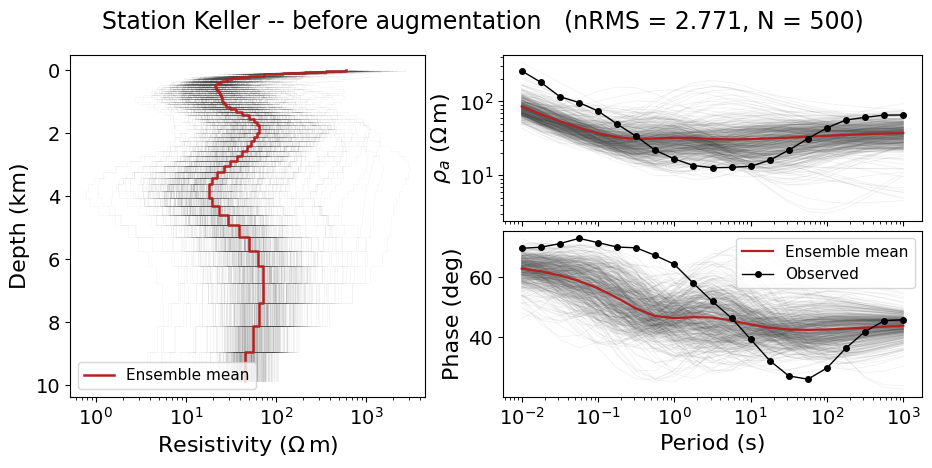

In [5]:
depths_km = ctx.grid.depths / 1e3
key = f"nRMS_{NRMS_CONVENTION}"

fig_before = plot_ensemble(before["Labels_est"], before["AppRes_real"], before["Phase_real"], obs, depths_km,
                           nrms=summary["before"][key], n_members=summary["before"]["n_neighbors_used"],
                           title=f"Station {STATION_ID.capitalize()} -- before augmentation",
                           loc_res="lower left", loc_resp="upper right", resp_legend_on="phase")
fig_before.savefig(FIG_DIR / f"fig_ensemble_{STATION_ID}_before.png", dpi=200, bbox_inches="tight")
plt.show()

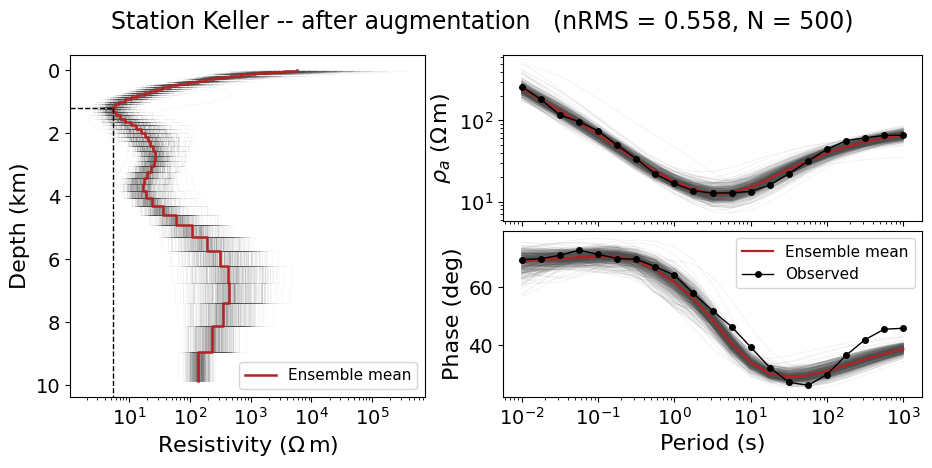

minimum ensemble-mean resistivity: 5.38 ohm-m in the layer 1.155-1.243 km (plotted at 1.199 km)


In [6]:
fig_after = plot_ensemble(after["Labels_est"], after["AppRes_real"], after["Phase_real"], obs, depths_km,
                          nrms=summary["after"][key], n_members=summary["after"]["n_neighbors_used"],
                          title=f"Station {STATION_ID.capitalize()} -- after augmentation",
                          loc_res="lower right", loc_resp="upper right", resp_legend_on="phase", mark_min=True)
fig_after.savefig(FIG_DIR / f"fig_ensemble_{STATION_ID}_after.png", dpi=200, bbox_inches="tight")
plt.show()

m = fig_after.mark_info
print(f"minimum ensemble-mean resistivity: {m['rho_min']:.3g} ohm-m in the layer {m['layer_km'][0]:.3f}-{m['layer_km'][1]:.3f} km "
      f"(plotted at {m['z_min_km']:.3f} km)")

## 5. How the catalog evolved (optional)

The evolution of the same station across five stages.

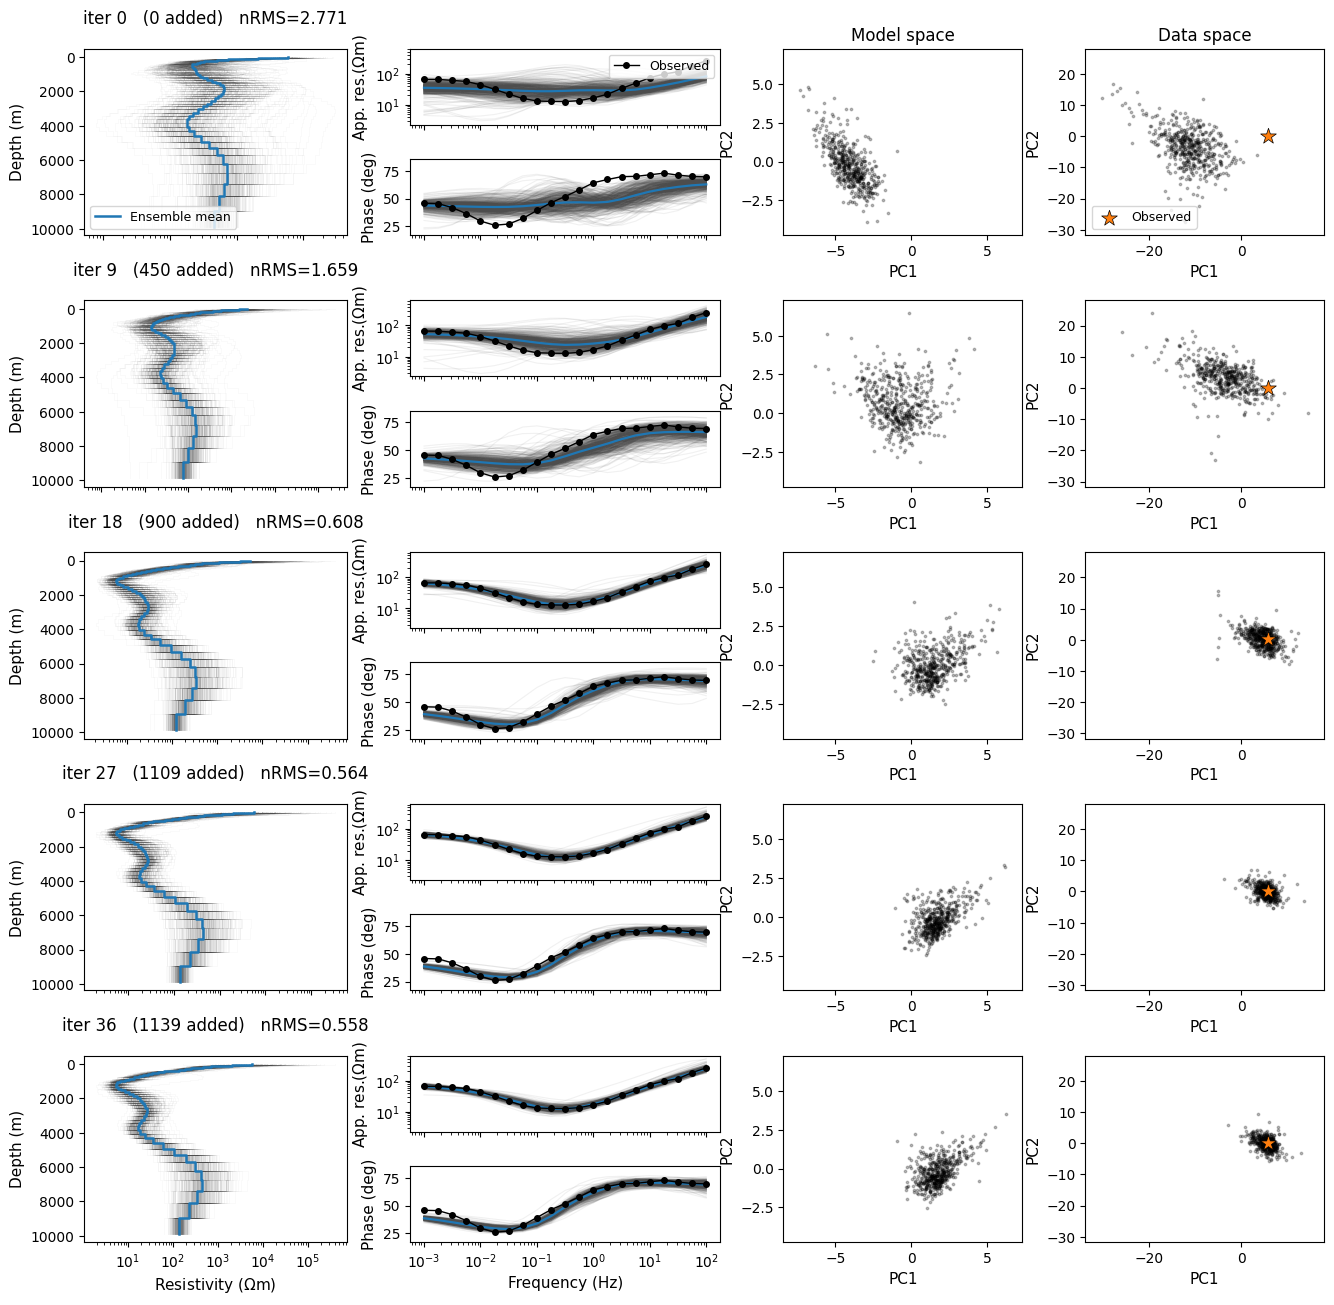

In [7]:
rows5 = run.evolution_rows(n_rows=5)
fig_evo = plot_evolution(rows5, obs, ctx.grid.depths, ctx.whitener.ref_std, ctx.config.noise)
fig_evo.savefig(FIG_DIR / f"fig_evolution_{STATION_ID}.png", dpi=160, bbox_inches="tight")
plt.show()